In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kyanyoga/sample-sales-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'sample-sales-data' dataset.
Path to dataset files: /kaggle/input/sample-sales-data


In [4]:
df = pd.read_csv("/kaggle/input/sample-sales-data/sales_data_sample.csv", encoding="latin1")

In [5]:
# Group sales data customer-wise
customer_data = df.groupby("CUSTOMERNAME")[["SALES", "QUANTITYORDERED"]].sum()


In [6]:
# Apply standard scaling
sc = StandardScaler()
X = sc.fit_transform(customer_data)


In [7]:
# Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

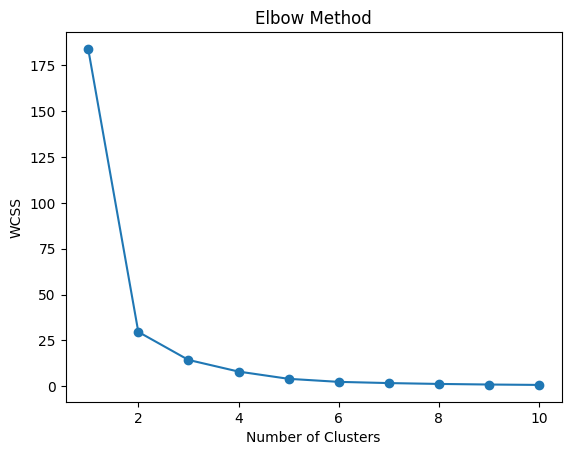

In [8]:
# Plot Elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [9]:
# K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_data["KMeans_Cluster"] = kmeans.fit_predict(X)

print("K-Means Clustering:")
print(customer_data.head())

K-Means Clustering:
                             SALES  QUANTITYORDERED  KMeans_Cluster
CUSTOMERNAME                                                       
AV Stores, Co.           157807.81             1778               0
Alpha Cognac              70488.44              687               2
Amica Models & Co.        94117.26              843               2
Anna's Decorations, Ltd  153996.13             1469               0
Atelier graphique         24179.96              270               2


In [10]:
# Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=3)
customer_data["Hierarchical_Cluster"] = hc.fit_predict(X)

print("Hierarchical Clustering:")
print(customer_data.head())



Hierarchical Clustering:
                             SALES  QUANTITYORDERED  KMeans_Cluster  \
CUSTOMERNAME                                                          
AV Stores, Co.           157807.81             1778               0   
Alpha Cognac              70488.44              687               2   
Amica Models & Co.        94117.26              843               2   
Anna's Decorations, Ltd  153996.13             1469               0   
Atelier graphique         24179.96              270               2   

                         Hierarchical_Cluster  
CUSTOMERNAME                                   
AV Stores, Co.                              2  
Alpha Cognac                                1  
Amica Models & Co.                          1  
Anna's Decorations, Ltd                     2  
Atelier graphique                           1  


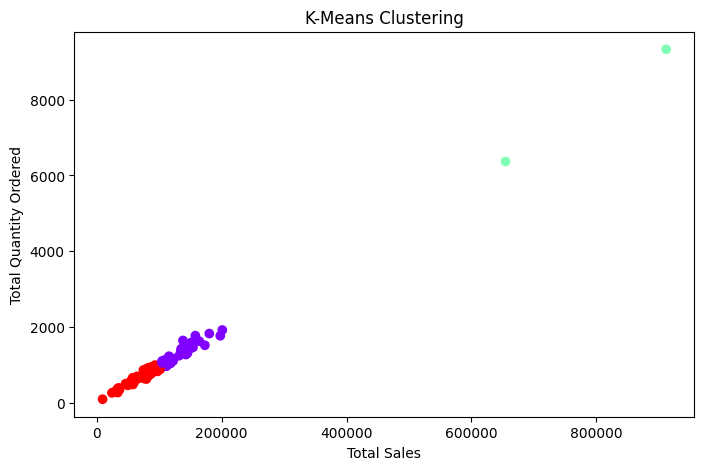

In [11]:

# Visualizing K-Means clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_data["SALES"],
    customer_data["QUANTITYORDERED"],
    c=customer_data["KMeans_Cluster"],
    cmap="rainbow"
)

plt.xlabel("Total Sales")
plt.ylabel("Total Quantity Ordered")
plt.title("K-Means Clustering")
plt.show()


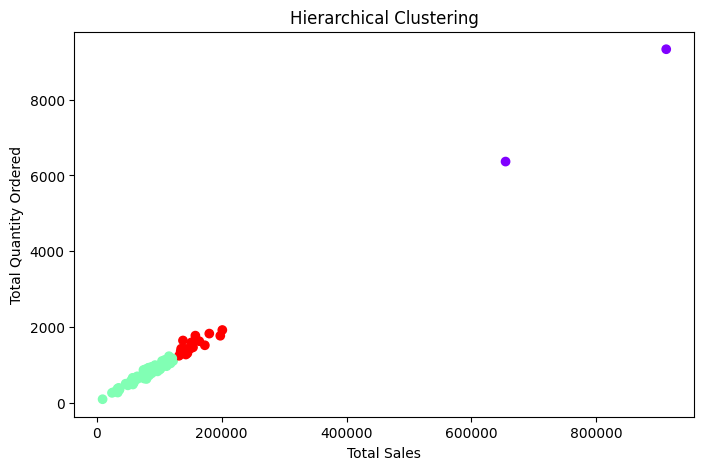

In [12]:

# Visualizing Hierarchical clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_data["SALES"],
    customer_data["QUANTITYORDERED"],
    c=customer_data["Hierarchical_Cluster"],
    cmap="rainbow"
)

plt.xlabel("Total Sales")
plt.ylabel("Total Quantity Ordered")
plt.title("Hierarchical Clustering")
plt.show()
